# 06 — Model B evaluation and fair development comparison

This notebook compares the frozen embedding baseline (Model A) and the fine-tuned ResNet-18 (Model B) on exactly the same internal-validation studies. It is a development comparison only. The official MURA valid split is not read or used for a new decision.

In [ ]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

## Load internal-validation predictions

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ModuleNotFoundError:
    pass

DATA_DIR = Path(os.environ.get("MURA_DATA_DIR", "/content/drive/MyDrive/DATA"))
MODEL_A_DIR = DATA_DIR / "BASELINE_MODEL_A"
MODEL_B_DIR = DATA_DIR / "MODEL_B_FINE_TUNING"
OUTPUT_DIR = DATA_DIR / "MODEL_A_MODEL_B_COMPARISON"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_a = pd.read_csv(MODEL_A_DIR / "validation_predictions.csv")
model_b = pd.read_csv(MODEL_B_DIR / "validation_predictions.csv")
model_a = model_a.rename(columns={"abnormal_probability": "model_a_probability"})
model_b = model_b.rename(columns={"abnormal_probability": "model_b_probability"})

common = model_a.merge(
    model_b[["patient_id", "study_id", "label", "num_views", "model_b_probability"]],
    on=["patient_id", "study_id", "label", "num_views"],
    how="inner",
    validate="one_to_one",
)
assert len(common) == len(model_a) == len(model_b)
assert common["study_id"].is_unique
assert common["label"].isin([0, 1]).all()
display(common.head())

## Ranking metrics

In [ ]:
def ranking_metrics(labels, scores):
    return {
        "AUROC": float(roc_auc_score(labels, scores)),
        "AUPRC": float(average_precision_score(labels, scores)),
    }

ranking = pd.DataFrame([
    {"model": "Model A: frozen embeddings plus Logistic Regression", **ranking_metrics(common["label"], common["model_a_probability"])},
    {"model": "Model B: fine-tuned ResNet-18", **ranking_metrics(common["label"], common["model_b_probability"])},
])
display(ranking)

## Sensitivity-constrained operating policy

In [ ]:
PRIMARY_SENSITIVITY_TARGET = 0.90

def metrics_at_threshold(labels, scores, threshold):
    predicted = (np.asarray(scores) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predicted, labels=[0, 1]).ravel()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    return {
        "threshold": float(threshold),
        "sensitivity": float(sensitivity),
        "specificity": float(specificity),
        "precision": float(precision_score(labels, predicted, zero_division=0)),
        "f1": float(f1_score(labels, predicted, zero_division=0)),
        "false_negative": int(fn),
        "false_positive": int(fp),
        "flagged_percent": float(100 * predicted.mean()),
        "youden_j": float(sensitivity + specificity - 1),
    }

def make_threshold_table(labels, scores):
    thresholds = np.unique(np.append(np.asarray(scores, dtype=float), 0.50))[::-1]
    return pd.DataFrame([metrics_at_threshold(labels, scores, threshold) for threshold in thresholds])

def select_policy(table, target):
    eligible = table.loc[table["sensitivity"] >= target].copy()
    if eligible.empty:
        raise RuntimeError(f"No threshold achieved sensitivity >= {target:.0%}")
    return eligible.sort_values(["threshold", "specificity"], ascending=[False, False]).iloc[0].to_dict()

policies = []
threshold_tables = {}
for model_name, score_column in [
    ("Model A: frozen embeddings plus Logistic Regression", "model_a_probability"),
    ("Model B: fine-tuned ResNet-18", "model_b_probability"),
]:
    table = make_threshold_table(common["label"], common[score_column])
    threshold_tables[score_column] = table
    chosen = select_policy(table, PRIMARY_SENSITIVITY_TARGET)
    policies.append({"model": model_name, "policy": "sensitivity >= 90%", **chosen})
    table.to_csv(OUTPUT_DIR / f"{score_column}_threshold_table.csv", index=False)

operating_points = pd.DataFrame(policies)
display(operating_points)

## Patient-cluster bootstrap interval

In [ ]:
def bootstrap_interval(frame, score_column, threshold, seed=42, iterations=1000):
    # Resample patient clusters. Integer study weights exactly represent drawing
    # a patient more than once, without repeatedly copying the same rows.
    rng = np.random.default_rng(seed)
    patient_codes, _ = pd.factorize(frame["patient_id"].astype(str), sort=False)
    labels = frame["label"].to_numpy(dtype=int)
    scores = frame[score_column].to_numpy(dtype=float)
    samples = []
    for _ in range(iterations):
        drawn = rng.integers(0, patient_codes.max() + 1, size=patient_codes.max() + 1)
        weights_by_patient = np.bincount(drawn, minlength=patient_codes.max() + 1)
        sample_weight = weights_by_patient[patient_codes]
        if not np.any(sample_weight[labels == 0]) or not np.any(sample_weight[labels == 1]):
            continue
        predicted = scores >= threshold
        tn = sample_weight[(labels == 0) & ~predicted].sum()
        fp = sample_weight[(labels == 0) & predicted].sum()
        fn = sample_weight[(labels == 1) & ~predicted].sum()
        tp = sample_weight[(labels == 1) & predicted].sum()
        samples.append({
            "AUROC": roc_auc_score(labels, scores, sample_weight=sample_weight),
            "AUPRC": average_precision_score(labels, scores, sample_weight=sample_weight),
            "sensitivity": tp / (tp + fn),
            "specificity": tn / (tn + fp),
        })
    samples = pd.DataFrame(samples)
    return {
        metric: (
            float(samples[metric].quantile(0.025)),
            float(samples[metric].quantile(0.975)),
        )
        for metric in samples.columns
    }

bootstrap_rows = []
for _, policy in operating_points.iterrows():
    score_column = "model_a_probability" if policy["model"].startswith("Model A") else "model_b_probability"
    intervals = bootstrap_interval(common, score_column, policy["threshold"])
    bootstrap_rows.append({
        "model": policy["model"],
        "AUROC_95_CI": intervals["AUROC"],
        "AUPRC_95_CI": intervals["AUPRC"],
        "sensitivity_95_CI": intervals["sensitivity"],
        "specificity_95_CI": intervals["specificity"],
    })
bootstrap_summary = pd.DataFrame(bootstrap_rows)
display(bootstrap_summary)

## Curves and workload comparison

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for model_name, score_column, color in [
    ("Model A", "model_a_probability", "tab:blue"),
    ("Model B", "model_b_probability", "tab:orange"),
]:
    fpr, tpr, _ = roc_curve(common["label"], common[score_column])
    precision, recall, _ = precision_recall_curve(common["label"], common[score_column])
    axes[0].plot(fpr, tpr, color=color, label=f"{model_name}: AUROC {roc_auc_score(common['label'], common[score_column]):.3f}")
    axes[1].plot(recall, precision, color=color, label=f"{model_name}: AUPRC {average_precision_score(common['label'], common[score_column]):.3f}")

axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(xlabel="False positive rate", ylabel="Sensitivity", title="Internal-validation ROC")
axes[1].set(xlabel="Sensitivity", ylabel="Precision", title="Internal-validation precision-recall")
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(operating_points[["model", "threshold", "sensitivity", "specificity", "precision", "false_negative", "false_positive", "flagged_percent"]])

## Save development-only comparison

In [ ]:
comparison = ranking.merge(
    operating_points[["model", "threshold", "sensitivity", "specificity", "precision", "f1", "false_negative", "false_positive", "flagged_percent"]],
    on="model",
    how="left",
)
comparison.to_csv(OUTPUT_DIR / "internal_validation_model_comparison.csv", index=False)
bootstrap_summary.to_csv(OUTPUT_DIR / "internal_validation_bootstrap_intervals.csv", index=False)
(OUTPUT_DIR / "governance.json").write_text(json.dumps({
    "split": "internal_validation",
    "official_mura_valid_read": False,
    "threshold_selection": "highest threshold with sensitivity >= 90% on internal validation",
    "limitation": "These are development estimates. The same internal validation split supports early stopping and operating policy selection.",
}, indent=2), encoding="utf-8")
display(comparison)

## Interpretation boundary

Both models are compared fairly because they predict the same studies. This is still not a new untouched final-test comparison, and it does not establish clinical deployment readiness.

## Published output snapshot

Fair comparison on the same internal-validation studies; not an untouched test result.

In [1]:
# Aggregate comparison for all evaluated study-level methods.
from pathlib import Path
import pandas as pd
comparison = pd.read_csv(Path('../docs/results/checkpoint1/model_comparison.csv'))
columns = ['model', 'auroc', 'auprc', 'sensitivity_at_target', 'specificity_at_target', 'false_negative_at_target', 'false_positive_at_target', 'flagged_percent_at_target']
notebook_summary = comparison[columns].rename(columns={
    'model': 'Model', 'auroc': 'AUROC', 'auprc': 'AUPRC',
    'sensitivity_at_target': 'Sensitivity @ ≥90% policy',
    'specificity_at_target': 'Specificity @ ≥90% policy',
    'false_negative_at_target': 'False negatives',
    'false_positive_at_target': 'False positives',
    'flagged_percent_at_target': 'Flagged for review (%)',
})
for column in ['AUROC', 'AUPRC', 'Sensitivity @ ≥90% policy', 'Specificity @ ≥90% policy', 'Flagged for review (%)']:
    notebook_summary[column] = notebook_summary[column].round(3)
display(notebook_summary)

Model,AUROC,AUPRC,Sensitivity @ ≥90% policy,Specificity @ ≥90% policy,False negatives,False positives,Flagged for review (%)
Frozen ResNet-18 + Logistic Regression,0.880,0.852,0.903,0.531,26,198,63.821
Fine-tuned ResNet-18 mean pooling,0.913,0.878,0.903,0.706,26,124,53.111
Fine-tuned ResNet-18 max pooling,0.883,0.806,0.903,0.711,26,122,52.822


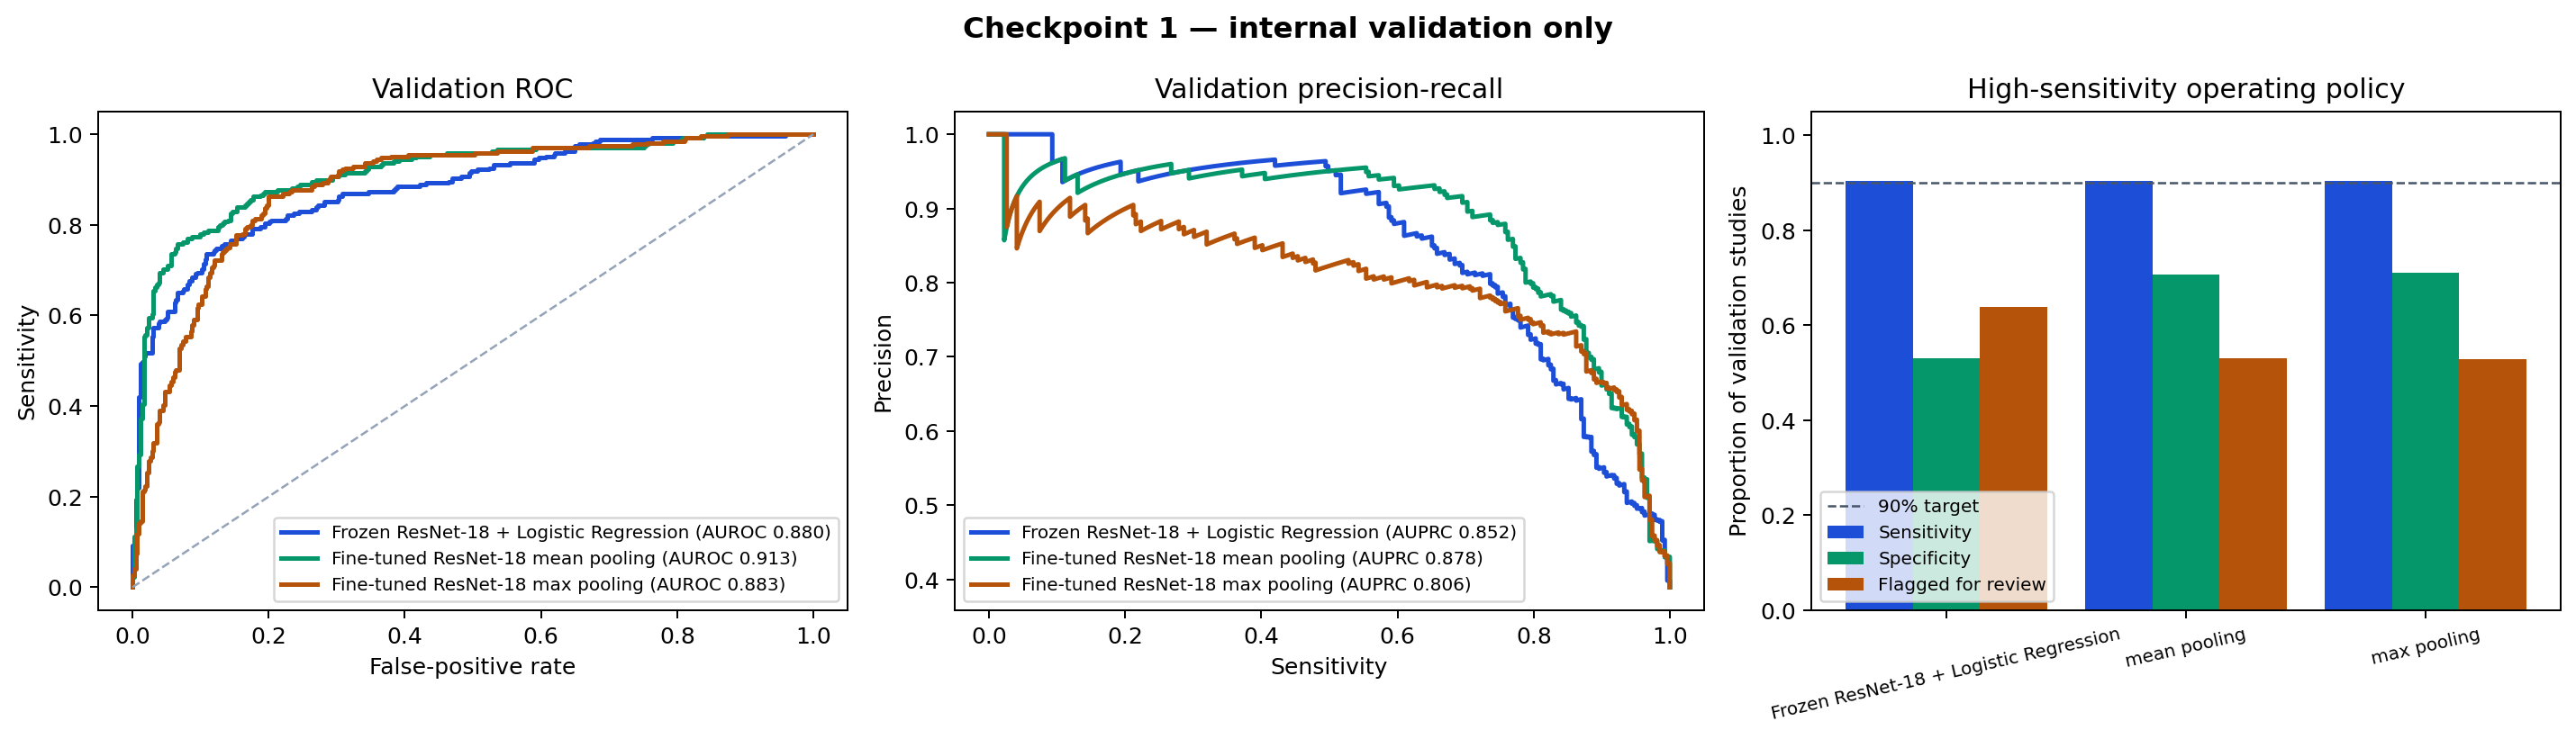

In [1]:
# ROC, precision–recall, and high-sensitivity workload comparison.
from IPython.display import Image, display
display(Image(filename='../docs/results/checkpoint1/validation_model_comparison.png'))